In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score, StratifiedKFold

RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)
print("Libraries loaded")

Libraries loaded


In [3]:
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
# Shorter, consistent column names ("Genre" in the file means gender)
df = df.rename(columns={
    "CustomerID": "customer_id",
    "Genre": "gender",
    "Age": "age",
    "Annual Income (k$)": "income",
    "Spending Score (1-100)": "spending",
})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  200 non-null    int64 
 1   gender       200 non-null    object
 2   age          200 non-null    int64 
 3   income       200 non-null    int64 
 4   spending     200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
df.describe()

,customer_id,age,income,spending
count,200.000,200.000,200.000,200.000
mean,100.500,38.850,60.560,50.200
std,57.879,13.969,26.265,25.824
min,1.000,18.000,15.000,1.000
25%,50.750,28.750,41.500,34.750
50%,100.500,36.000,61.500,50.000
75%,150.250,49.000,78.000,73.000
max,200.000,70.000,137.000,99.000


In [6]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate customer IDs:", df["customer_id"].duplicated().sum())
print("\nGender counts:")
print(df["gender"].value_counts())

Missing values per column:
customer_id    0
gender         0
age            0
income         0
spending       0
dtype: int64

Duplicate customer IDs: 0

Gender counts:
gender
Female    112
Male       88
Name: count, dtype: int64


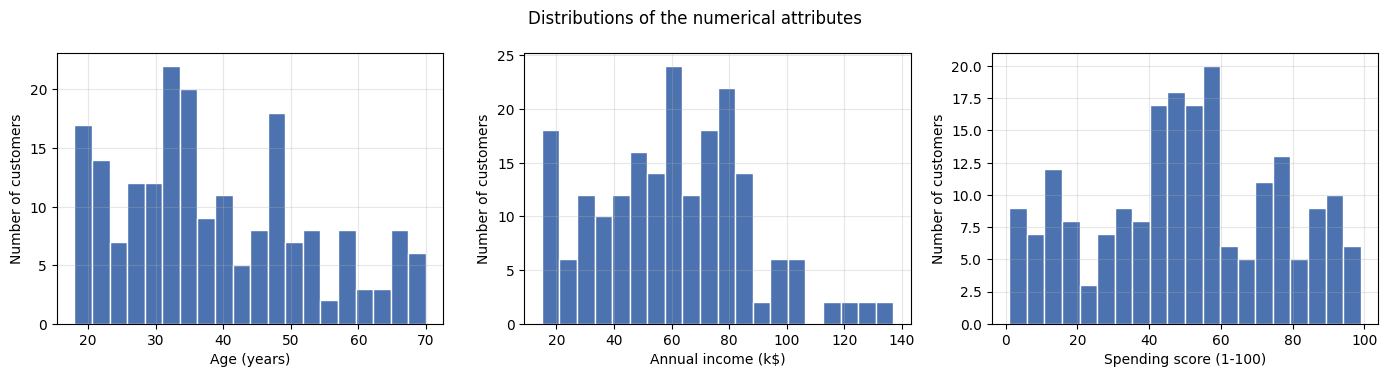

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, label in zip(axes, ["age", "income", "spending"],
                          ["Age (years)", "Annual income (k$)", "Spending score (1-100)"]):
    ax.hist(df[col], bins=20, color="#4C72B0", edgecolor="white")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of customers")
fig.suptitle("Distributions of the numerical attributes")
plt.tight_layout()
plt.show()

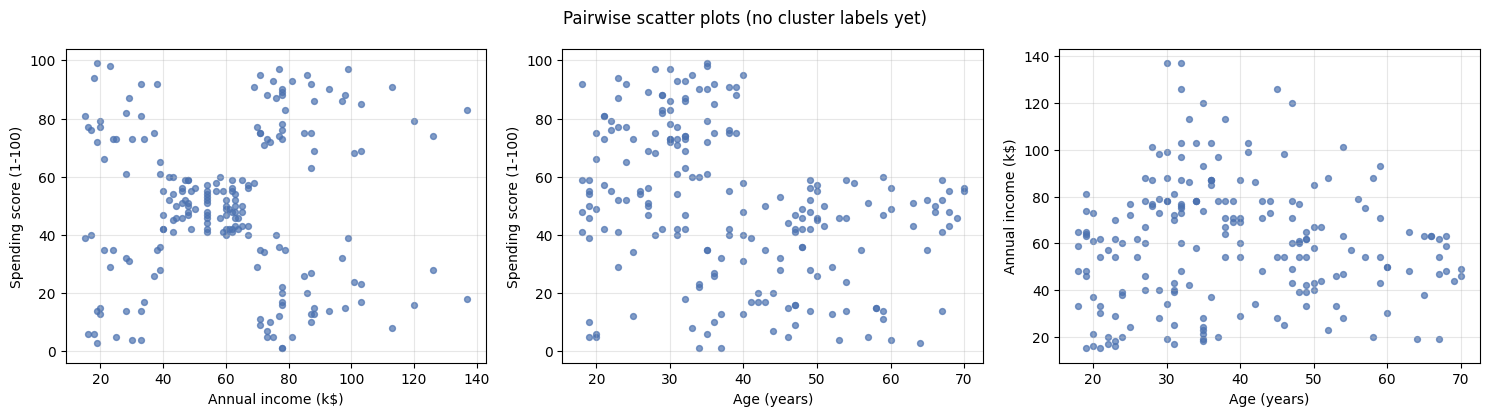

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
pairs = [("income", "spending"), ("age", "spending"), ("age", "income")]
labels = {"age": "Age (years)", "income": "Annual income (k$)", "spending": "Spending score (1-100)"}
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df[x], df[y], s=18, alpha=0.7, color="#4C72B0")
    ax.set_xlabel(labels[x]); ax.set_ylabel(labels[y])
fig.suptitle("Pairwise scatter plots (no cluster labels yet)")
plt.tight_layout()
plt.show()

In [9]:
df[["age", "income", "spending"]].corr().round(2)

,age,income,spending
age,1.00,-0.01,-0.33
income,-0.01,1.00,0.01
spending,-0.33,0.01,1.00


In [10]:
# Customer ID is only an identifier and gender is binary, so neither is used for distance-based clustering.
features = ["income", "spending"]
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

comparison = pd.DataFrame({
    "before: mean": X.mean(axis=0), "before: std": X.std(axis=0),
    "before: min": X.min(axis=0), "before: max": X.max(axis=0),
    "after: mean": X_scaled.mean(axis=0), "after: std": X_scaled.std(axis=0),
    "after: min": X_scaled.min(axis=0), "after: max": X_scaled.max(axis=0),
}, index=features)
comparison.round(2)

,before: mean,before: std,before: min,before: max,after: mean,after: std,after: min,after: max
income,60.56,26.20,15,137,-0.0,1.0,-1.74,2.92
spending,50.20,25.76,1,99,-0.0,1.0,-1.91,1.89


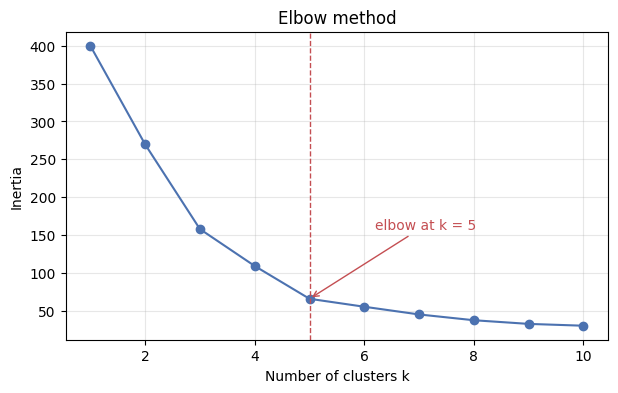

,inertia,drop vs previous k
k,,
1,400.0,NaN
2,269.7,130.3
3,157.7,112.0
4,108.9,48.8
5,65.6,43.4
6,55.1,10.5
7,44.9,10.2
8,37.2,7.6
9,32.4,4.8


In [11]:
#Choosing the number of clusters
k_values = range(1, 11)
inertias = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, "o-", color="#4C72B0")
plt.axvline(5, color="#C44E52", ls="--", lw=1)
plt.annotate("elbow at k = 5", xy=(5, inertias[4]), xytext=(6.2, inertias[2]),
             arrowprops=dict(arrowstyle="->", color="#C44E52"), color="#C44E52")
plt.xlabel("Number of clusters k"); plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

pd.DataFrame({"k": list(k_values), "inertia": np.round(inertias, 1),
              "drop vs previous k": np.r_[np.nan, -np.diff(inertias)].round(1)}).set_index("k")

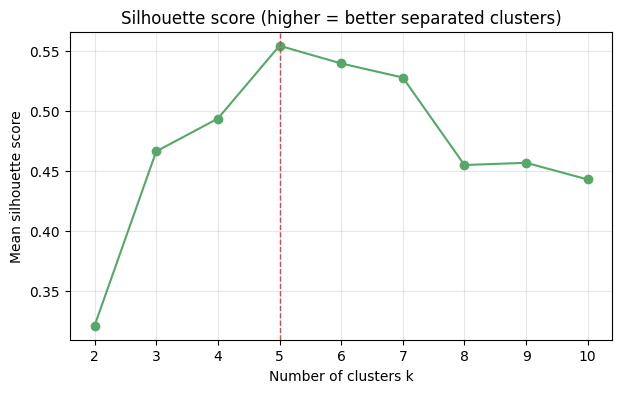

{2: np.float64(0.321), 3: np.float64(0.467), 4: np.float64(0.494), 5: np.float64(0.555), 6: np.float64(0.54), 7: np.float64(0.528), 8: np.float64(0.455), 9: np.float64(0.457), 10: np.float64(0.443)}


In [12]:
#silhouette score
sil = {}
for k in range(2, 11):
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    sil[k] = silhouette_score(X_scaled, labels_k)

plt.figure(figsize=(7, 4))
plt.plot(list(sil.keys()), list(sil.values()), "o-", color="#55A868")
plt.axvline(5, color="#C44E52", ls="--", lw=1)
plt.xlabel("Number of clusters k"); plt.ylabel("Mean silhouette score")
plt.title("Silhouette score (higher = better separated clusters)")
plt.show()
print({k: round(v, 3) for k, v in sil.items()})

In [13]:
#Training K-Means and interpreting the clusters
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_scaled)
df["cluster"] = kmeans.labels_

print("Inertia:", round(kmeans.inertia_, 2))
print("Silhouette:", round(silhouette_score(X_scaled, kmeans.labels_), 3))
print("\nCluster centers (scaled units):")
print(kmeans.cluster_centers_.round(2))

centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centers["size"] = df["cluster"].value_counts().sort_index().values
centers.index.name = "cluster"
centers.round(1)

Inertia: 65.57
Silhouette: 0.555

Cluster centers (scaled units):
[[-0.2  -0.03]
 [ 0.99  1.24]
 [-1.33  1.13]
 [ 1.06 -1.28]
 [-1.31 -1.14]]


,income,spending,size
cluster,,,
0,55.3,49.5,81
1,86.5,82.1,39
2,25.7,79.4,22
3,88.2,17.1,35
4,26.3,20.9,23


In [14]:
# Give each cluster a business name from the position of its center (original units)
def name_segment(income, spending):
    if income >= 70 and spending >= 60:
        return "Target customers"
    if income >= 70 and spending < 40:
        return "Careful high earners"
    if income < 40 and spending >= 60:
        return "Enthusiastic spenders"
    if income < 40 and spending < 40:
        return "Budget-conscious"
    return "Average customers"

centers["segment"] = [name_segment(i, s) for i, s in zip(centers["income"], centers["spending"])]
segment_of = centers["segment"].to_dict()
df["segment"] = df["cluster"].map(segment_of)
centers.round(1)

,income,spending,size,segment
cluster,,,,
0,55.3,49.5,81,Average customers
1,86.5,82.1,39,Target customers
2,25.7,79.4,22,Enthusiastic spenders
3,88.2,17.1,35,Careful high earners
4,26.3,20.9,23,Budget-conscious


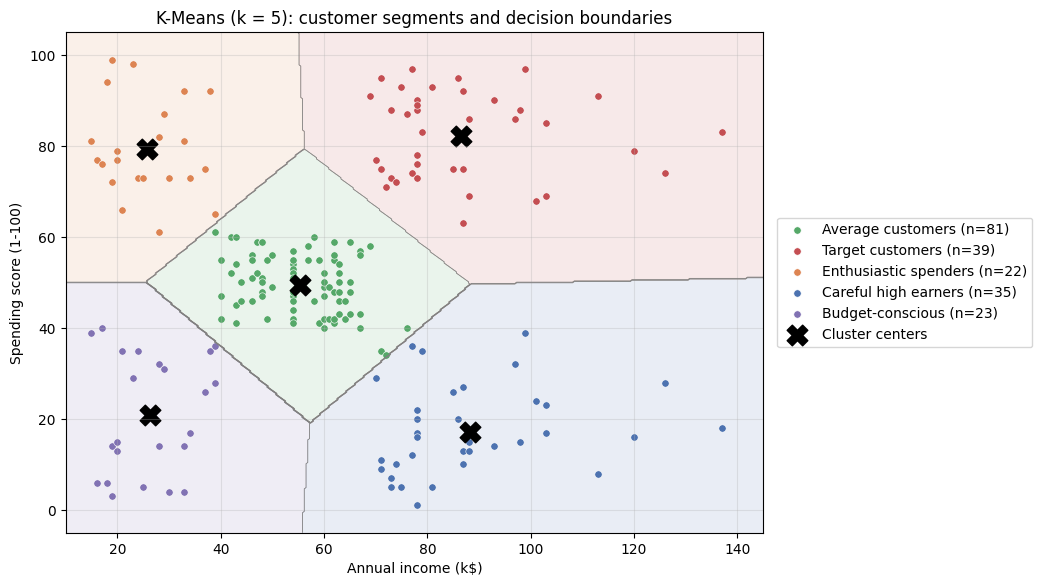

In [15]:
colors = {"Target customers": "#C44E52", "Careful high earners": "#4C72B0",
          "Enthusiastic spenders": "#DD8452", "Budget-conscious": "#8172B3",
          "Average customers": "#55A868"}

# Decision boundaries: predict the cluster of every point on a fine grid
xx, yy = np.meshgrid(np.linspace(10, 145, 400), np.linspace(-5, 105, 400))
grid = scaler.transform(np.c_[xx.ravel(), yy.ravel()])
zz = kmeans.predict(grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.contourf(xx, yy, zz, levels=np.arange(K + 1) - 0.5, alpha=0.12,
            colors=[colors[segment_of[c]] for c in range(K)])
ax.contour(xx, yy, zz, levels=np.arange(K + 1) - 0.5, colors="grey", linewidths=0.6)
for c in range(K):
    part = df[df["cluster"] == c]
    ax.scatter(part["income"], part["spending"], s=28, color=colors[segment_of[c]],
               label=f"{segment_of[c]} (n={len(part)})", edgecolor="white", linewidth=0.4)
ax.scatter(centers["income"], centers["spending"], marker="X", s=220, color="black", label="Cluster centers")
ax.set_xlabel("Annual income (k$)"); ax.set_ylabel("Spending score (1-100)")
ax.set_title("K-Means (k = 5): customer segments and decision boundaries")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

In [16]:
#Random initialization and stability
# n_init = 1: a single random start per run, repeated with 10 different seeds
single = []
for seed in range(10):
    km = KMeans(n_clusters=K, init="random", n_init=1, random_state=seed).fit(X_scaled)
    single.append({"seed": seed, "inertia": round(km.inertia_, 2),
                   "agreement with final model (ARI)": round(adjusted_rand_score(kmeans.labels_, km.labels_), 3)})
single = pd.DataFrame(single).set_index("seed")

multi = KMeans(n_clusters=K, init="random", n_init=10, random_state=0).fit(X_scaled)
print("n_init = 10 inertia:", round(multi.inertia_, 2))
single

n_init = 10 inertia: 65.57


,inertia,agreement with final model (ARI)
seed,,
0,65.57,1.000
1,65.57,1.000
2,98.76,0.703
3,65.57,1.000
4,133.00,0.501
5,65.57,1.000
6,65.58,0.985
7,99.18,0.714
8,111.98,0.723


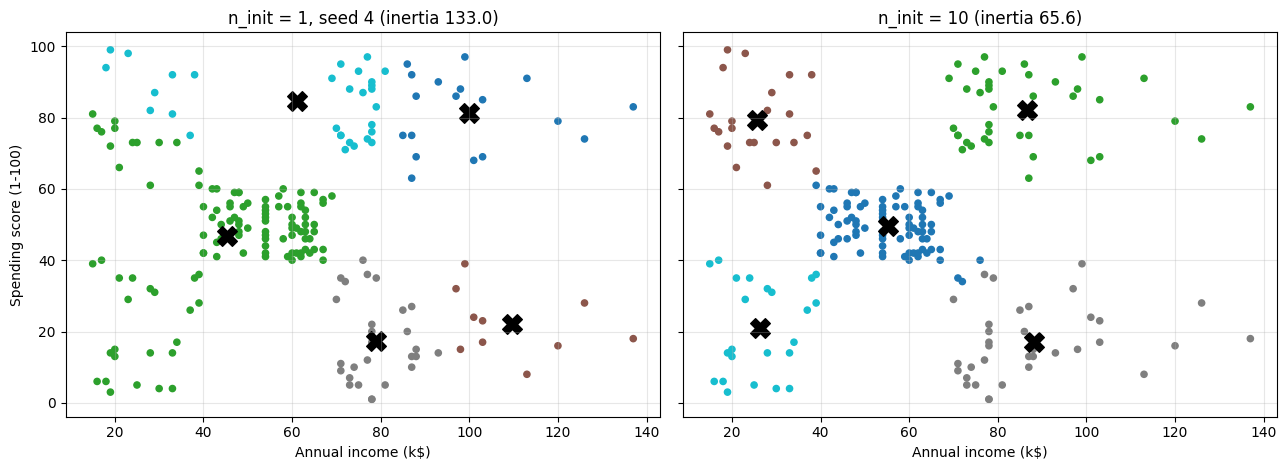

In [17]:
worst_seed = single["inertia"].idxmax()
worst = KMeans(n_clusters=K, init="random", n_init=1, random_state=int(worst_seed)).fit(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, model, title in [(axes[0], worst, f"n_init = 1, seed {worst_seed} (inertia {worst.inertia_:.1f})"),
                         (axes[1], kmeans, f"n_init = 10 (inertia {kmeans.inertia_:.1f})")]:
    ax.scatter(df["income"], df["spending"], c=model.labels_, cmap="tab10", s=20)
    c = scaler.inverse_transform(model.cluster_centers_)
    ax.scatter(c[:, 0], c[:, 1], marker="X", s=200, color="black")
    ax.set_title(title); ax.set_xlabel("Annual income (k$)")
axes[0].set_ylabel("Spending score (1-100)")
plt.tight_layout()
plt.show()

In [18]:
#Mini-Batch K-Means
rows = []
for name, model in [("KMeans", KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)),
                    ("MiniBatchKMeans", MiniBatchKMeans(n_clusters=K, n_init=10, batch_size=64,
                                                        random_state=RANDOM_STATE))]:
    t0 = time.perf_counter()
    model.fit(X_scaled)
    rows.append({"model": name, "time (ms)": round((time.perf_counter() - t0) * 1000, 1),
                 "inertia": round(model.inertia_, 2),
                 "silhouette": round(silhouette_score(X_scaled, model.labels_), 3),
                 "agreement with KMeans (ARI)": round(adjusted_rand_score(kmeans.labels_, model.labels_), 3)})
pd.DataFrame(rows).set_index("model")

,time (ms),inertia,silhouette,agreement with KMeans (ARI)
model,,,,
KMeans,56.3,65.57,0.555,1.000
MiniBatchKMeans,32.6,66.60,0.553,0.942


In [19]:
# Engineered features
df["ratio"] = df["spending"] / df["income"]          # spending points per k$ of income
df["young"] = (df["age"] < 40).astype(int)            # 1 = under 40
df["male"] = (df["gender"] == "Male").astype(int)     # gender as 0/1

feature_sets = {
    "Income + Spending (baseline)": ["income", "spending"],
    "+ Spending/Income ratio": ["income", "spending", "ratio"],
    "+ Young flag (age < 40)": ["income", "spending", "young"],
    "+ Age": ["age", "income", "spending"],
    "+ Age + Gender (0/1)": ["age", "income", "spending", "male"],
}
def bootstrap_stability(Xs, k, n_boot=10, seed=0):
    """Mean agreement (ARI) between models fitted on two different bootstrap samples."""
    rng = np.random.default_rng(seed)
    scores = []
    for r in range(n_boot):
        a = rng.choice(len(Xs), len(Xs)); b = rng.choice(len(Xs), len(Xs))
        la = KMeans(k, n_init=10, random_state=r).fit(Xs[a]).predict(Xs)
        lb = KMeans(k, n_init=10, random_state=r + 100).fit(Xs[b]).predict(Xs)
        scores.append(adjusted_rand_score(la, lb))
    return np.mean(scores)

def random_reference(cols, seed=0):
    """Same-size data with no structure: base attributes drawn uniformly over their real ranges,
    gender drawn at random, and the engineered features recomputed from these random values."""
    rng = np.random.default_rng(seed)
    n = len(df)
    r = pd.DataFrame({c: rng.uniform(df[c].min(), df[c].max(), n) for c in ["age", "income", "spending"]})
    r["male"] = rng.integers(0, 2, n)
    r["ratio"] = r["spending"] / r["income"]
    r["young"] = (r["age"] < 40).astype(int)
    return r[cols].values

print("Engineered features added:", ["ratio", "young", "male"])

Engineered features added: ['ratio', 'young', 'male']


In [20]:
results = []
for name, cols in feature_sets.items():
    Xs = StandardScaler().fit_transform(df[cols])
    sil_k = {k: silhouette_score(Xs, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xs))
             for k in range(2, 9)}
    best_k = max(sil_k, key=sil_k.get)
    # reference: best silhouette on structure-free data, averaged over 5 random datasets
    refs = []
    for seed in range(5):
        Xr = StandardScaler().fit_transform(random_reference(cols, seed))
        refs.append(max(silhouette_score(Xr, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xr))
                        for k in range(2, 9)))
    ref = np.mean(refs)
    results.append({"feature set": name, "best k": best_k,
                    "silhouette at best k": round(sil_k[best_k], 3),
                    "silhouette at k = 5": round(sil_k[5], 3),
                    "random-data reference": round(ref, 3),
                    "gain over random": round(sil_k[best_k] - ref, 3),
                    "stability at k = 5 (ARI)": round(bootstrap_stability(Xs, 5), 2)})
fe_results = pd.DataFrame(results).set_index("feature set")
fe_results

,best k,silhouette at best k,silhouette at k = 5,random-data reference,gain over random,stability at k = 5 (ARI)
feature set,,,,,,
Income + Spending (baseline),5,0.555,0.555,0.431,0.124,0.95
+ Spending/Income ratio,6,0.536,0.533,0.420,0.115,0.92
+ Young flag (age < 40),8,0.558,0.485,0.432,0.126,0.82
+ Age,6,0.428,0.417,0.319,0.109,0.79
+ Age + Gender (0/1),8,0.388,0.304,0.297,0.091,0.68


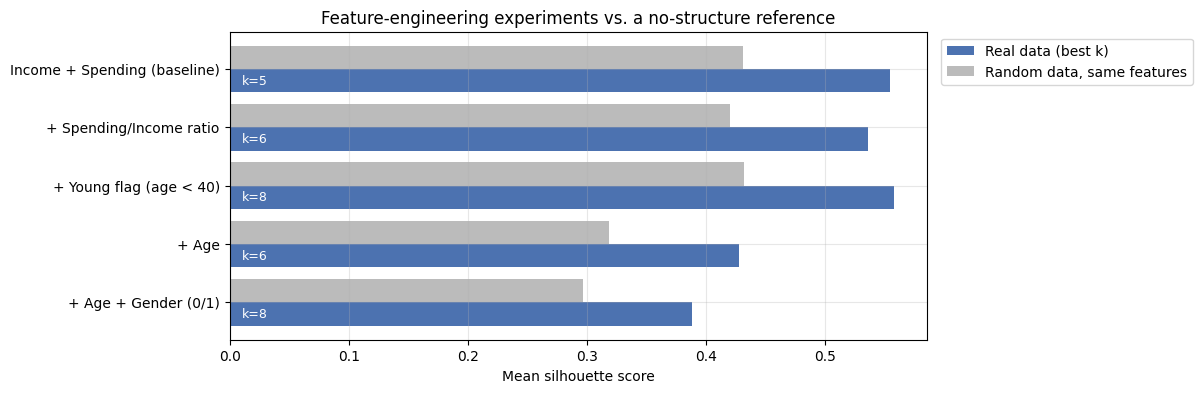

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(fe_results))
ax.barh(y + 0.2, fe_results["silhouette at best k"], height=0.4, color="#4C72B0", label="Real data (best k)")
ax.barh(y - 0.2, fe_results["random-data reference"], height=0.4, color="#BBBBBB", label="Random data, same features")
ax.set_yticks(y); ax.set_yticklabels(fe_results.index); ax.invert_yaxis()
for yi, k in zip(y, fe_results["best k"]):
    ax.text(0.01, yi + 0.2, f"k={k}", va="center", color="white", fontsize=9)
ax.set_xlabel("Mean silhouette score")
ax.set_title("Feature-engineering experiments vs. a no-structure reference")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [22]:
#Describing the segments with engineered features
df["age_group"] = pd.cut(df["age"], bins=[17, 29, 39, 49, 59, 70],
                         labels=["18-29", "30-39", "40-49", "50-59", "60-70"])

profile = df.groupby("segment").agg(
    customers=("customer_id", "count"),
    avg_income_k=("income", "mean"),
    avg_spending=("spending", "mean"),
    avg_age=("age", "mean"),
    spend_per_k_income=("ratio", "mean"),
    pct_under_40=("young", "mean"),
    pct_female=("male", lambda s: 1 - s.mean()),
)
profile["share_of_customers"] = profile["customers"] / len(df)
for c in ["pct_under_40", "pct_female", "share_of_customers"]:
    profile[c] = (profile[c] * 100).round(0)
order = ["Target customers", "Careful high earners", "Average customers",
         "Enthusiastic spenders", "Budget-conscious"]
profile = profile.loc[order]
profile.round(2)

,customers,avg_income_k,avg_spending,avg_age,spend_per_k_income,pct_under_40,pct_female,share_of_customers
segment,,,,,,,,
Target customers,39,86.54,82.13,32.69,0.98,97.0,54.0,20.0
Careful high earners,35,88.20,17.11,41.11,0.19,40.0,46.0,18.0
Average customers,81,55.30,49.52,42.72,0.93,42.0,59.0,40.0
Enthusiastic spenders,22,25.73,79.36,25.27,3.37,100.0,59.0,11.0
Budget-conscious,23,26.30,20.91,45.22,0.86,35.0,61.0,12.0


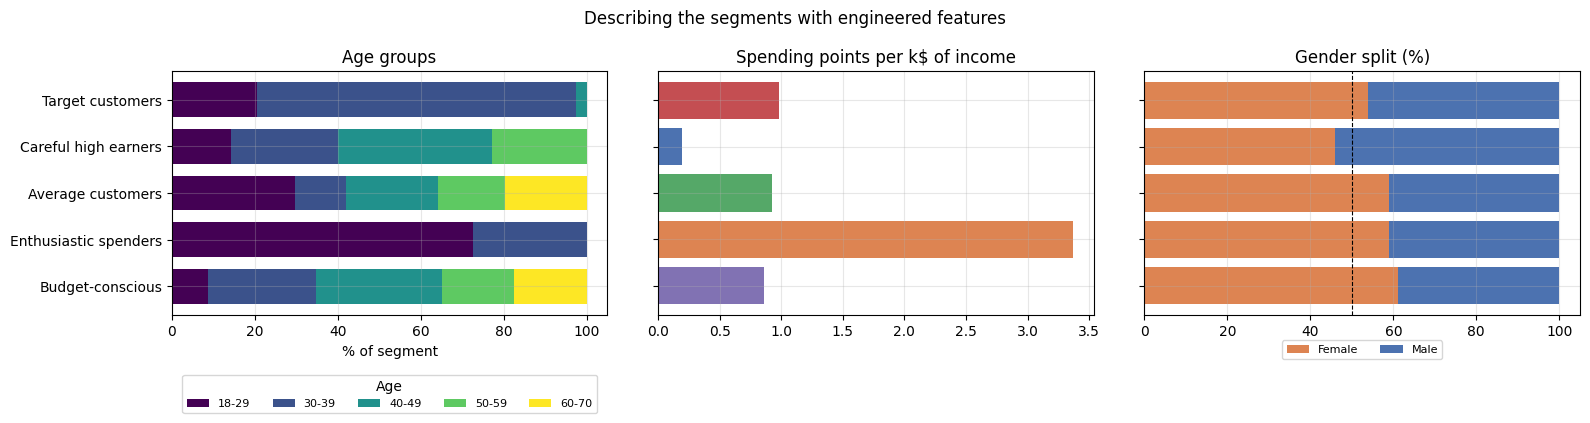

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1) Age-group mix per segment
mix = pd.crosstab(df["segment"], df["age_group"], normalize="index").loc[order] * 100
mix.plot(kind="barh", stacked=True, ax=axes[0], colormap="viridis", width=0.75)
axes[0].set_xlabel("% of segment"); axes[0].set_ylabel(""); axes[0].invert_yaxis()
axes[0].set_title("Age groups"); axes[0].legend(title="Age", fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=5)

# 2) Spending per k$ of income
axes[1].barh(order, profile["spend_per_k_income"], color=[colors[s] for s in order])
axes[1].invert_yaxis(); axes[1].set_title("Spending points per k$ of income"); axes[1].set_yticklabels([])

# 3) Gender split
axes[2].barh(order, profile["pct_female"], color="#DD8452", label="Female")
axes[2].barh(order, 100 - profile["pct_female"], left=profile["pct_female"], color="#4C72B0", label="Male")
axes[2].axvline(50, color="black", lw=0.8, ls="--")
axes[2].invert_yaxis(); axes[2].set_title("Gender split (%)"); axes[2].set_yticklabels([])
axes[2].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)

fig.suptitle("Describing the segments with engineered features")
plt.tight_layout()
plt.show()

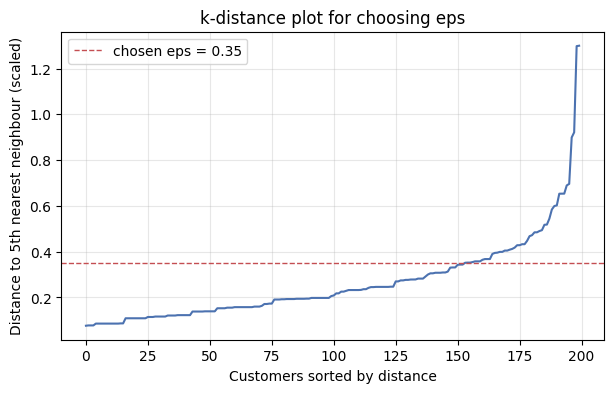

Percentiles (50, 75, 90, 95): [0.21 0.33 0.47 0.6 ]


In [24]:
#Validating the segments with DBSCAN (extension)
MIN_SAMPLES = 5
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled)
k_dist = np.sort(nn.kneighbors(X_scaled)[0][:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist, color="#4C72B0")
plt.axhline(0.35, color="#C44E52", ls="--", lw=1, label="chosen eps = 0.35")
plt.xlabel("Customers sorted by distance"); plt.ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour (scaled)")
plt.title("k-distance plot for choosing eps")
plt.legend()
plt.show()
print("Percentiles (50, 75, 90, 95):", np.percentile(k_dist, [50, 75, 90, 95]).round(2))

In [25]:
dbscan = DBSCAN(eps=0.35, min_samples=MIN_SAMPLES).fit(X_scaled)
df["dbscan"] = dbscan.labels_
n_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
noise = (dbscan.labels_ == -1)
print("DBSCAN clusters:", n_clusters)
print("Customers labelled as noise:", noise.sum(), f"({noise.mean():.0%})")
print("Agreement with K-Means on non-noise customers (ARI):",
      round(adjusted_rand_score(df.loc[~noise, "cluster"], df.loc[~noise, "dbscan"]), 3))

pd.crosstab(df["segment"], df["dbscan"].replace(-1, "noise"), margins=True)

DBSCAN clusters: 6
Customers labelled as noise: 23 (12%)
Agreement with K-Means on non-noise customers (ARI): 0.875


dbscan,0,1,2,3,4,5,noise,All
segment,,,,,,,,
Average customers,0,0,0,81,0,0,0,81
Budget-conscious,0,12,7,3,0,0,1,23
Careful high earners,0,0,0,3,0,23,9,35
Enthusiastic spenders,16,0,0,1,0,0,5,22
Target customers,0,0,0,0,31,0,8,39
All,16,12,7,88,31,23,23,200


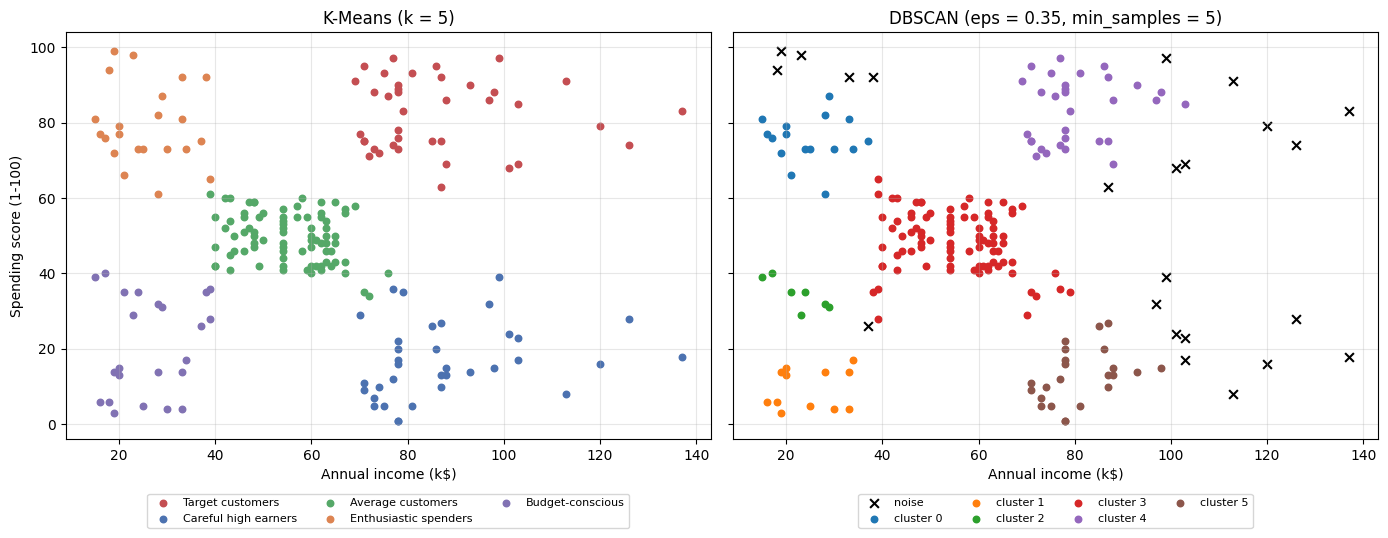

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for s in order:
    p = df[df["segment"] == s]
    axes[0].scatter(p["income"], p["spending"], s=22, color=colors[s], label=s)
axes[0].set_title("K-Means (k = 5)"); axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)

palette = plt.cm.tab10.colors
for lab in sorted(df["dbscan"].unique()):
    p = df[df["dbscan"] == lab]
    if lab == -1:
        axes[1].scatter(p["income"], p["spending"], s=40, marker="x", color="black", label="noise")
    else:
        axes[1].scatter(p["income"], p["spending"], s=22, color=palette[lab], label=f"cluster {lab}")
axes[1].set_title("DBSCAN (eps = 0.35, min_samples = 5)"); axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
for ax in axes:
    ax.set_xlabel("Annual income (k$)")
axes[0].set_ylabel("Spending score (1-100)")
plt.tight_layout()
plt.show()

In [27]:
#Sensitivity to the settings
rows = []
for eps in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    for ms in [5, 8]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        m = lab != -1
        rows.append({"eps": eps, "min_samples": ms,
                     "clusters": len(set(lab[m])),
                     "noise customers": int((~m).sum()),
                     "ARI vs K-Means": round(adjusted_rand_score(df.loc[m, "cluster"], lab[m]), 2)})
pd.DataFrame(rows).set_index(["eps", "min_samples"])

clusters  noise customers  ARI vs K-Means
eps  min_samples                                           
0.25 5                   6               50            0.87
     8                   5               79            0.92
0.30 5                   7               35            0.85
     8                   5               72            0.90
0.35 5                   6               23            0.88
     8                   4               55            0.89
0.40 5                   4               15            0.59
     8                   5               25            0.79
0.45 5                   3               11            0.34
     8                   3               19            0.37
0.50 5                   2                8            0.26
     8                   2               15            0.28

In [28]:
# Labels from K-Means become the target; the tree learns readable rules for assigning new members
X_clf = df[["income", "spending"]]
y_clf = df["segment"]
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(tree, X_clf, y_clf, cv=cv, scoring="f1_macro")
print("5-fold cross-validated macro F1:", scores.round(3), "mean =", round(scores.mean(), 3))

tree.fit(X_clf, y_clf)
print("\nRules marketing can apply:\n")
print(export_text(tree, feature_names=["income_k", "spending"]))

5-fold cross-validated macro F1: [0.913 0.96  0.981 0.959 0.956] mean = 0.953

Rules marketing can apply:

|--- income_k <= 69.50
|   |--- income_k <= 39.50
|   |   |--- spending <= 50.50
|   |   |   |--- class: Budget-conscious
|   |   |--- spending >  50.50
|   |   |   |--- class: Enthusiastic spenders
|   |--- income_k >  39.50
|   |   |--- spending <= 75.50
|   |   |   |--- class: Average customers
|   |   |--- spending >  75.50
|   |   |   |--- class: Target customers
|--- income_k >  69.50
|   |--- spending <= 51.50
|   |   |--- spending <= 33.00
|   |   |   |--- class: Careful high earners
|   |   |--- spending >  33.00
|   |   |   |--- class: Average customers
|   |--- spending >  51.50
|   |   |--- class: Target customers



In [29]:
new_members = pd.DataFrame({"income": [25, 120, 60, 95], "spending": [85, 90, 50, 12]})
new_members["segment (tree)"] = tree.predict(new_members[["income", "spending"]])
new_members["segment (k-means)"] = [segment_of[c] for c in kmeans.predict(scaler.transform(new_members[["income", "spending"]].values))]
new_members

,income,spending,segment (tree),segment (k-means)
0,25,85,Enthusiastic spenders,Enthusiastic spenders
1,120,90,Target customers,Target customers
2,60,50,Average customers,Average customers
3,95,12,Careful high earners,Careful high earners
